In [1]:
%pip install -U ultralytics opencv-python matplotlib pandas numpy seaborn scikit-learn pillow pyyaml tqdm


In [2]:
from pathlib import Path
import os
import json
import time
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import cv2

import torch
import torch.nn as nn

from ultralytics import YOLO

print("PyTorch    :", torch.__version__)
print("Ultralytics imported successfully")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch    : 2.11.0+cu130
Ultralytics imported successfully


In [3]:
print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Device      :", torch.cuda.get_device_name(0))
else:
    print("Device          : CPU (Tip: In Colab, Runtime -> Change runtime type -> T4 GPU)")


PyTorch version : 2.11.0+cu130
CUDA available  : True
GPU Device      : Tesla T4


In [10]:
!unzip -q /content/chenab_dataset/chenab_dataset.zip -d /content/chenab_dataset/

In [11]:
PROJECT_ROOT = Path("/content/fabric_defect_detection")

# Automatically locate dataset folder in Colab
if Path("/content/chenab_dataset").exists():
    DATASET_DIR = Path("/content/chenab_dataset")
elif (PROJECT_ROOT / "data" / "chenab_yolov12_cpu_paper_reproduction").exists():
    DATASET_DIR = PROJECT_ROOT / "data" / "chenab_yolov12_cpu_paper_reproduction"
else:
    DATASET_DIR = Path("/content/chenab_dataset")

DATA_YAML = DATASET_DIR / "data.yaml"

RUNS_DIR = PROJECT_ROOT / "runs"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

for d in [RUNS_DIR, RESULTS_DIR, MODELS_DIR, OUTPUTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT ROOT :", PROJECT_ROOT)
print("DATASET      :", DATASET_DIR)
print("DATA YAML    :", DATA_YAML)
print("RUNS         :", RUNS_DIR)
print("RESULTS      :", RESULTS_DIR)
print("MODELS       :", MODELS_DIR)
print("OUTPUTS      :", OUTPUTS_DIR)


PROJECT ROOT : /content/fabric_defect_detection
DATASET      : /content/chenab_dataset
DATA YAML    : /content/chenab_dataset/data.yaml
RUNS         : /content/fabric_defect_detection/runs
RESULTS      : /content/fabric_defect_detection/results
MODELS       : /content/fabric_defect_detection/models
OUTPUTS      : /content/fabric_defect_detection/outputs


In [12]:
assert PROJECT_ROOT.exists(), f"Project not found: {PROJECT_ROOT}"
assert DATASET_DIR.exists(), f"Dataset not found: {DATASET_DIR}"
assert DATA_YAML.exists(), f"data.yaml not found: {DATA_YAML}"

print("Dataset verified successfully.\nContents:")
for item in sorted(DATASET_DIR.iterdir()):
    print(" -", item.name)


Dataset verified successfully.
Contents:
 - README.roboflow.txt
 - chenab_dataset.zip
 - data.yaml
 - paper_reproduction.yaml
 - test
 - train
 - valid


In [13]:
with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

print(json.dumps(data_config, indent=4))


{
    "train": "../train/images",
    "val": "../valid/images",
    "test": "../test/images",
    "nc": 7,
    "names": [
        "baekra",
        "color issues",
        "contamination",
        "cut",
        "gray stitch",
        "selvet",
        "stain"
    ],
    "roboflow": {
        "workspace": "seecs-z4uae",
        "project": "fabricdd",
        "version": 2,
        "license": "Private",
        "url": "https://app.roboflow.com/seecs-z4uae/fabricdd/2"
    }
}


In [14]:
CLASS_NAMES = data_config["names"]

if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = list(CLASS_NAMES.values())

NUM_CLASSES = len(CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name}")


Number of classes: 7
0: baekra
1: color issues
2: contamination
3: cut
4: gray stitch
5: selvet
6: stain


In [15]:
B2_DATA_YAML = OUTPUTS_DIR / "chenab_b2_p2.yaml"

b2_config = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": CLASS_NAMES
}

with open(B2_DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(b2_config, f, sort_keys=False)

print("Created:", B2_DATA_YAML)
print()
print(B2_DATA_YAML.read_text())


Created: /content/fabric_defect_detection/outputs/chenab_b2_p2.yaml

path: /content/chenab_dataset
train: train/images
val: valid/images
test: test/images
names:
- baekra
- color issues
- contamination
- cut
- gray stitch
- selvet
- stain



In [16]:
IMG_SIZE = 640
EPOCHS = 50

# Automatically leverage Colab GPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 16 if torch.cuda.is_available() else 2
WORKERS = 2 if torch.cuda.is_available() else 0

# Paper-inspired settings
LEARNING_RATE = 0.005
FINAL_LR_FACTOR = 0.01
MOMENTUM = 0.97
WEIGHT_DECAY = 0.0005
WARMUP_EPOCHS = 7

HSV_H = 0.025
HSV_S = 0.7
HSV_V = 0.5

MOSAIC = 0.3
PATIENCE = 10

RUN_NAME = "chenab_yolov12n_p2_run"

print("Model       : YOLOv12n + P2 (4 Detection Scales)")
print("Image size  :", IMG_SIZE)
print("Epochs      :", EPOCHS)
print("Batch size  :", BATCH_SIZE)
print("Device      :", DEVICE)
print("Workers     :", WORKERS)


Model       : YOLOv12n + P2 (4 Detection Scales)
Image size  : 640
Epochs      : 50
Batch size  : 16
Device      : 0
Workers     : 2


In [17]:
P2_MODEL_YAML = OUTPUTS_DIR / "yolo12n_p2.yaml"

p2_yaml = f"""
# YOLOv12n + P2 (Four-scale custom configuration)
# Four-scale detector: P2/4 - P3/8 - P4/16 - P5/32

nc: {NUM_CLASSES}

scales:
  # [depth, width, max_channels]
  n: [0.50, 0.25, 1024]

backbone:
  # [from, repeats, module, args]
  - [-1, 1, Conv, [64, 3, 2]]              # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]             # 1-P2/4
  - [-1, 2, C3k2, [256, False, 0.25]]      # 2
  - [-1, 1, Conv, [256, 3, 2]]             # 3-P3/8
  - [-1, 2, C3k2, [512, False, 0.25]]      # 4
  - [-1, 1, Conv, [512, 3, 2]]             # 5-P4/16
  # At P4 scale (512 * 0.25 = 128 channels): c_ = 128 * 0.5 = 64 (multiple of 32 ✓)
  - [-1, 4, A2C2f, [512, True, 4]]         # 6
  - [-1, 1, Conv, [1024, 3, 2]]            # 7-P5/32
  # At P5 scale (1024 * 0.25 = 256 channels): c_ = 256 * 0.5 = 128 (multiple of 32 ✓)
  - [-1, 4, A2C2f, [1024, True, 1]]        # 8

head:
  # P5 -> P4
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]  # 9
  - [[-1, 6], 1, Concat, [1]]                    # 10
  - [-1, 2, A2C2f, [512, False, 4]]             # 11 P4

  # P4 -> P3
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]  # 12
  - [[-1, 4], 1, Concat, [1]]                    # 13
  - [-1, 2, C3k2, [256, False, 0.25]]           # 14 P3 (Use C3k2 to avoid ABlock assertion on small channels)

  # P3 -> P2 (New layer scale)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]  # 15
  - [[-1, 1], 1, Concat, [1]]                    # 16
  - [-1, 2, C3k2, [128, False, 0.25]]           # 17 P2 (Use C3k2 to avoid ABlock assertion on small channels)

  # P2 -> P3
  - [-1, 1, Conv, [128, 3, 2]]                  # 18
  - [[-1, 14], 1, Concat, [1]]                  # 19
  - [-1, 2, C3k2, [256, False, 0.25]]           # 20 P3

  # P3 -> P4
  - [-1, 1, Conv, [256, 3, 2]]                  # 21
  - [[-1, 11], 1, Concat, [1]]                  # 22
  - [-1, 2, A2C2f, [512, False, 4]]             # 23 P4

  # P4 -> P5
  - [-1, 1, Conv, [512, 3, 2]]                  # 24
  - [[-1, 8], 1, Concat, [1]]                   # 25
  - [-1, 2, C3k2, [1024, True]]                 # 26 P5

  # Four-scale detect
  - [[17, 20, 23, 26], 1, Detect, [nc]]
"""

with open(P2_MODEL_YAML, "w", encoding="utf-8") as f:
    f.write(p2_yaml.strip())

print("Created:", P2_MODEL_YAML)


Created: /content/fabric_defect_detection/outputs/yolo12n_p2.yaml


In [19]:
p2_model = YOLO(str(P2_MODEL_YAML))
print("YOLOv12 with P2 head successfully instantiated!")
print(f"Number of model parameter groups: {len(p2_model.model.model)}")

YOLOv12 with P2 head successfully instantiated!
Number of model parameter groups: 28


In [20]:
p2_model.info()
print("\nDetailed Layer Sequence:")
for i, layer in enumerate(p2_model.model.model):
    print(f"{i:02d} | {layer.__class__.__name__}")


YOLO12n_p2 summary: 297 layers, 2,617,348 parameters, 2,617,332 gradients, 10.9 GFLOPs

Detailed Layer Sequence:
00 | Conv
01 | Conv
02 | C3k2
03 | Conv
04 | C3k2
05 | Conv
06 | A2C2f
07 | Conv
08 | A2C2f
09 | Upsample
10 | Concat
11 | A2C2f
12 | Upsample
13 | Concat
14 | C3k2
15 | Upsample
16 | Concat
17 | C3k2
18 | Conv
19 | Concat
20 | C3k2
21 | Conv
22 | Concat
23 | A2C2f
24 | Conv
25 | Concat
26 | C3k2
27 | Detect


In [21]:
print("Detection Head Layer:")
print(p2_model.model.model[-1])


Detection Head Layer:
Detect(
  (cv2): ModuleList(
    (0): Sequential(
      (0): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU()
      )
      (1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU()
      )
      (2): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
    )
    (1): Sequential(
      (0): Conv(
        (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU()
      )
      (1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNo

In [22]:
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
p2_model.model.eval()

with torch.no_grad():
    p2_output = p2_model.model(dummy_input)

print("P2 forward pass successful.")


P2 forward pass successful.


In [23]:
BASE_MODEL = "yolo12n.pt"
transfer_result = p2_model.load(BASE_MODEL)
print("YOLOv12n pretrained weights loaded.")
print(transfer_result)


Transferred 422/755 items from pretrained weights
YOLOv12n pretrained weights loaded.
YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU()
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU()
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU()
        )
        (cv2): Conv(
          (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps

In [24]:
p2_model.info()


YOLO12n_p2 summary: 297 layers, 2,617,348 parameters, 2,617,332 gradients, 10.9 GFLOPs


(297, 2617348, 2617332, 10.857216)

In [25]:
p2_model.model.eval()
with torch.no_grad():
    output = p2_model.model(dummy_input)

print("P2 forward pass after pretrained weight loading: SUCCESS")


P2 forward pass after pretrained weight loading: SUCCESS


In [26]:
baseline_model = YOLO("yolo12n.pt")

baseline_params = sum(p.numel() for p in baseline_model.model.parameters())
p2_params = sum(p.numel() for p in p2_model.model.parameters())

print("YOLOv12n parameters :", f"{baseline_params:,}")
print("YOLOv12n + P2       :", f"{p2_params:,}")
print("\nAdditional parameters:", f"{p2_params - baseline_params:,}")
print("Parameter increase   :", f"{((p2_params / baseline_params) - 1) * 100:.2f}%")


YOLOv12n parameters : 2,603,056
YOLOv12n + P2       : 2,617,348

Additional parameters: 14,292
Parameter increase   : 0.55%


In [27]:
start_time = time.time()

p2_results = p2_model.train(
    data=str(B2_DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    optimizer="SGD",
    lr0=LEARNING_RATE,
    lrf=FINAL_LR_FACTOR,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    warmup_epochs=WARMUP_EPOCHS,
    hsv_h=HSV_H,
    hsv_s=HSV_S,
    hsv_v=HSV_V,
    mosaic=MOSAIC,
    patience=PATIENCE,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    plots=True,
    exist_ok=True
)

training_time = time.time() - start_time
print("\n" + "=" * 60)
print("B2 TRAINING COMPLETE")
print("=" * 60)
print(f"Training time: {training_time / 60:.2f} minutes ({training_time:.1f} seconds)")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fabric_defect_detection/outputs/chenab_b2_p2.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.025, hsv_s=0.7, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/fabric_defect_detection/outputs/yolo12n_p2.yaml, momentum=0.97, mosaic=0.3, multi_s

In [28]:
B2_RUN_DIR = RUNS_DIR / RUN_NAME
B2_BEST = B2_RUN_DIR / "weights" / "best.pt"

print("Expected B2 model:", B2_BEST)
if B2_BEST.exists():
    print("\nB2 best.pt FOUND.")
else:
    print("\nbest.pt not found. Searching recursively...")
    found = list(RUNS_DIR.rglob("best.pt"))
    if found:
        B2_BEST = max(found, key=lambda p: p.stat().st_mtime)
        print("Found latest best.pt:", B2_BEST)


Expected B2 model: /content/fabric_defect_detection/runs/chenab_yolov12n_p2_run/weights/best.pt

B2 best.pt FOUND.


In [29]:
b2_model = YOLO(str(B2_BEST))
print("B2 trained model loaded successfully.")


B2 trained model loaded successfully.


In [30]:
b2_val_metrics = b2_model.val(
    data=str(B2_DATA_YAML),
    split="val",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    plots=True
)
print("B2 validation completed.")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO12n_p2 summary (fused): 174 layers, 2,605,952 parameters, 0 gradients, 10.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1418.7±975.4 MB/s, size: 60.6 KB)
val: Scanning /content/chenab_dataset/valid/labels.cache... 562 images, 38 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 562/562 214.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.4it/s 10.5s
                   all        562        786       0.61      0.523      0.574      0.303
                baekra         48         79      0.672      0.392      0.491      0.292
          color issues         15         30      0.366        0.2      0.239      0.114
         contamination         53         55      0.702      0.945       0.92       0.44
                   cut         75        102      0.675       0.49      0.569      0.313
           gray stitch         

In [31]:
b2_val_precision = float(b2_val_metrics.box.mp)
b2_val_recall = float(b2_val_metrics.box.mr)
b2_val_map50 = float(b2_val_metrics.box.map50)
b2_val_map5095 = float(b2_val_metrics.box.map)
b2_val_f1 = (2 * b2_val_precision * b2_val_recall / (b2_val_precision + b2_val_recall)) if (b2_val_precision + b2_val_recall) > 0 else 0.0

print("B2 VALIDATION RESULTS")

print(f"Precision : {b2_val_precision * 100:.2f}%")
print(f"Recall    : {b2_val_recall * 100:.2f}%")
print(f"F1        : {b2_val_f1 * 100:.2f}%")
print(f"mAP50     : {b2_val_map50 * 100:.2f}%")
print(f"mAP50-95  : {b2_val_map5095 * 100:.2f}%")


B2 VALIDATION RESULTS
Precision : 60.99%
Recall    : 52.27%
F1        : 56.30%
mAP50     : 57.44%
mAP50-95  : 30.34%


In [32]:
b2_test_metrics = b2_model.val(
    data=str(B2_DATA_YAML),
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    plots=True
)
print("B2 test evaluation completed.")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO12n_p2 summary (fused): 174 layers, 2,605,952 parameters, 0 gradients, 10.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1724.7±618.6 MB/s, size: 108.2 KB)
val: Scanning /content/chenab_dataset/test/labels... 280 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 280/280 2.1Kit/s 0.1s
val: New cache created: /content/chenab_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.7it/s 6.5s
                   all        280        368      0.631      0.523      0.588      0.293
                baekra         17         24      0.527      0.372      0.433      0.251
          color issues         14         21      0.432       0.19      0.285      0.136
         contamination         14         17      0.701      0.941      0.964      0.455
                   cut         41         47      0.688      0.

In [33]:
b2_precision = float(b2_test_metrics.box.mp)
b2_recall = float(b2_test_metrics.box.mr)
b2_map50 = float(b2_test_metrics.box.map50)
b2_map5095 = float(b2_test_metrics.box.map)
b2_f1 = (2 * b2_precision * b2_recall / (b2_precision + b2_recall)) if (b2_precision + b2_recall) > 0 else 0.0

print("=" * 60)
print("B2 TEST RESULTS — YOLOv12n + P2")
print("=" * 60)
print(f"Precision     : {b2_precision * 100:.2f}%")
print(f"Recall        : {b2_recall * 100:.2f}%")
print(f"F1-Score      : {b2_f1 * 100:.2f}%")
print(f"mAP@0.50      : {b2_map50 * 100:.2f}%")
print(f"mAP@0.50:0.95 : {b2_map5095 * 100:.2f}%")


B2 TEST RESULTS — YOLOv12n + P2
Precision     : 63.14%
Recall        : 52.26%
F1-Score      : 57.18%
mAP@0.50      : 58.85%
mAP@0.50:0.95 : 29.34%


In [34]:
# Exact Part A Test Baseline Values
part_a_baseline = {
    "Model": "YOLOv12n — PART A",
    "Precision": 79.74,
    "Recall": 70.78,
    "F1-Score": 74.99,
    "mAP@0.50": 80.55,
    "mAP@0.50:0.95": 47.42
}
part_a_baseline


{'Model': 'YOLOv12n — PART A',
 'Precision': 79.74,
 'Recall': 70.78,
 'F1-Score': 74.99,
 'mAP@0.50': 80.55,
 'mAP@0.50:0.95': 47.42}

In [35]:
b2_results = {
    "Model": "YOLOv12n + P2",
    "Precision": b2_precision * 100,
    "Recall": b2_recall * 100,
    "F1-Score": b2_f1 * 100,
    "mAP@0.50": b2_map50 * 100,
    "mAP@0.50:0.95": b2_map5095 * 100
}
b2_results


{'Model': 'YOLOv12n + P2',
 'Precision': 63.13691672180386,
 'Recall': 52.25748697347415,
 'F1-Score': 57.18434339064918,
 'mAP@0.50': 58.84514378623359,
 'mAP@0.50:0.95': 29.341796429994186}

In [36]:
comparison_b2 = pd.DataFrame([part_a_baseline, b2_results])
display(comparison_b2.style.format({
    "Precision": "{:.2f}%",
    "Recall": "{:.2f}%",
    "F1-Score": "{:.2f}%",
    "mAP@0.50": "{:.2f}%",
    "mAP@0.50:0.95": "{:.2f}%"
}))


,Model,Precision,Recall,F1-Score,mAP@0.50,mAP@0.50:0.95
0,YOLOv12n — PART A,79.74%,70.78%,74.99%,80.55%,47.42%
1,YOLOv12n + P2,63.14%,52.26%,57.18%,58.85%,29.34%


In [37]:
improvement_b2 = {}
for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    improvement_b2[metric] = b2_results[metric] - part_a_baseline[metric]

improvement_b2_df = pd.DataFrame([improvement_b2], index=["YOLOv12n + P2 (Diff)"])
display(improvement_b2_df.style.format("{:+.2f}%"))


,Precision,Recall,F1-Score,mAP@0.50,mAP@0.50:0.95
YOLOv12n + P2 (Diff),-16.60%,-18.52%,-17.81%,-21.70%,-18.08%


In [38]:
relative_b2 = {}
for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    baseline = part_a_baseline[metric]
    current = b2_results[metric]
    relative_b2[metric] = ((current - baseline) / baseline) * 100

relative_b2_df = pd.DataFrame([relative_b2], index=["YOLOv12n + P2 (% Change)"])
display(relative_b2_df.style.format("{:+.2f}%"))


,Precision,Recall,F1-Score,mAP@0.50,mAP@0.50:0.95
YOLOv12n + P2 (% Change),-20.82%,-26.17%,-23.74%,-26.95%,-38.12%


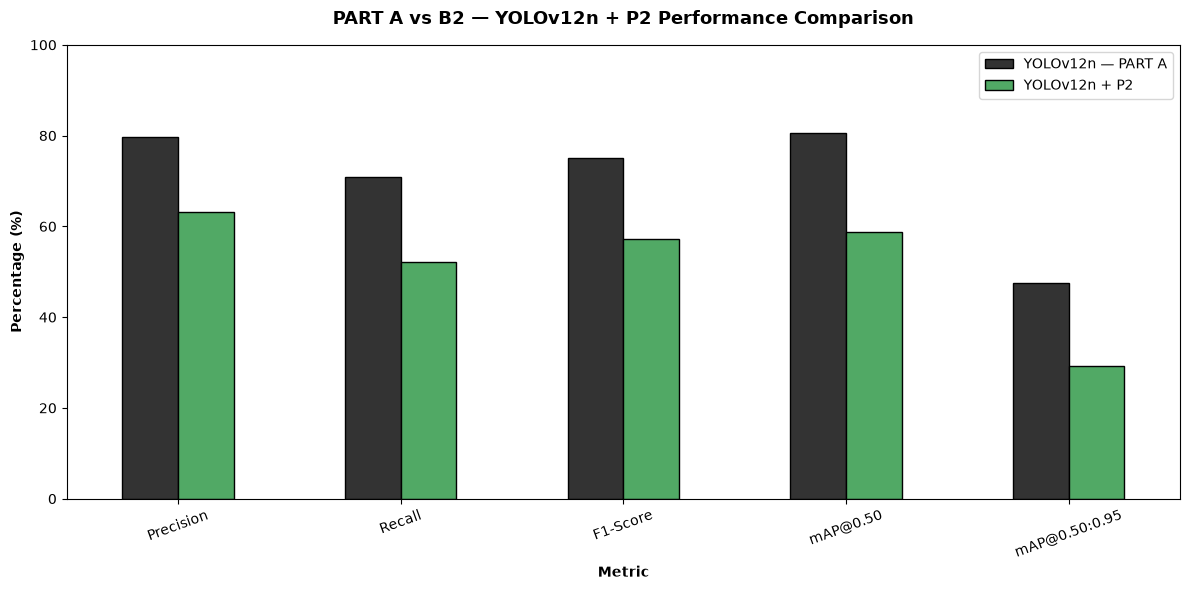

In [39]:
metrics_to_plot = ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]
plot_df = comparison_b2.set_index("Model")[metrics_to_plot]

plot_df.T.plot(kind="bar", figsize=(12, 6), color=["#333333", "#51a965"], edgecolor="black")
plt.ylabel("Percentage (%)", fontweight="bold")
plt.xlabel("Metric", fontweight="bold")
plt.title("PART A vs B2 — YOLOv12n + P2 Performance Comparison", fontsize=13, fontweight="bold", pad=15)
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


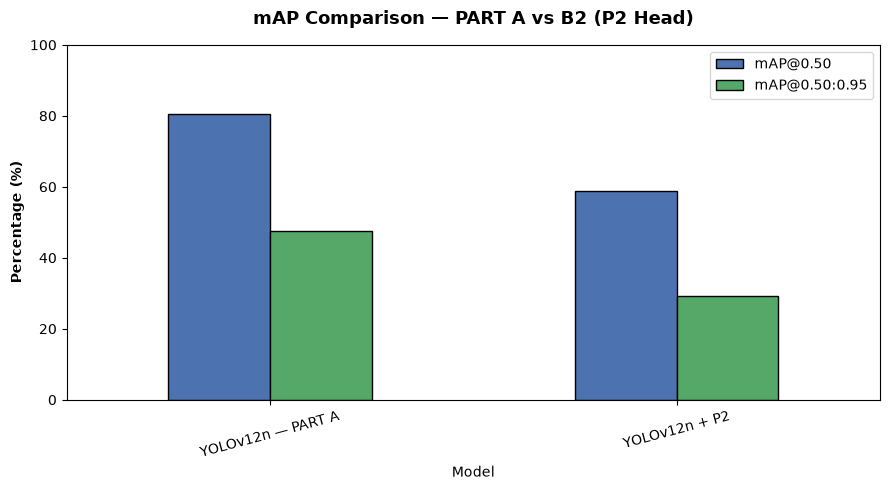

In [40]:
map_df = comparison_b2.set_index("Model")[["mAP@0.50", "mAP@0.50:0.95"]]

map_df.plot(kind="bar", figsize=(9, 5), color=["#4C72B0", "#55A868"], edgecolor="black")
plt.ylabel("Percentage (%)", fontweight="bold")
plt.title("mAP Comparison — PART A vs B2 (P2 Head)", fontsize=13, fontweight="bold", pad=15)
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


In [41]:
B2_RESULTS_CSV = B2_RUN_DIR / "results.csv"
print("Results CSV Path:", B2_RESULTS_CSV)

if B2_RESULTS_CSV.exists():
    b2_history = pd.read_csv(B2_RESULTS_CSV)
    b2_history.columns = [c.strip() for c in b2_history.columns]
    print("Available training metrics:", b2_history.columns.tolist())


Results CSV Path: /content/fabric_defect_detection/runs/chenab_yolov12n_p2_run/results.csv
Available training metrics: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


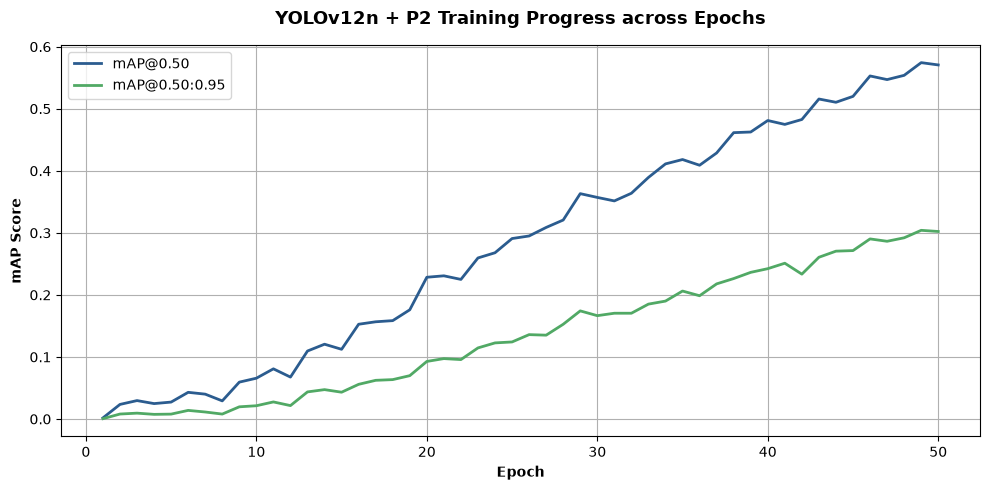

In [42]:
if B2_RESULTS_CSV.exists():
    plt.figure(figsize=(10, 5))
    plt.plot(b2_history["epoch"], b2_history["metrics/mAP50(B)"], label="mAP@0.50", color="#2b5c8f", linewidth=2)
    plt.plot(b2_history["epoch"], b2_history["metrics/mAP50-95(B)"], label="mAP@0.50:0.95", color="#51a965", linewidth=2)
    plt.xlabel("Epoch", fontweight="bold")
    plt.ylabel("mAP Score", fontweight="bold")
    plt.title("YOLOv12n + P2 Training Progress across Epochs", fontsize=13, fontweight="bold", pad=15)
    plt.legend(frameon=True)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


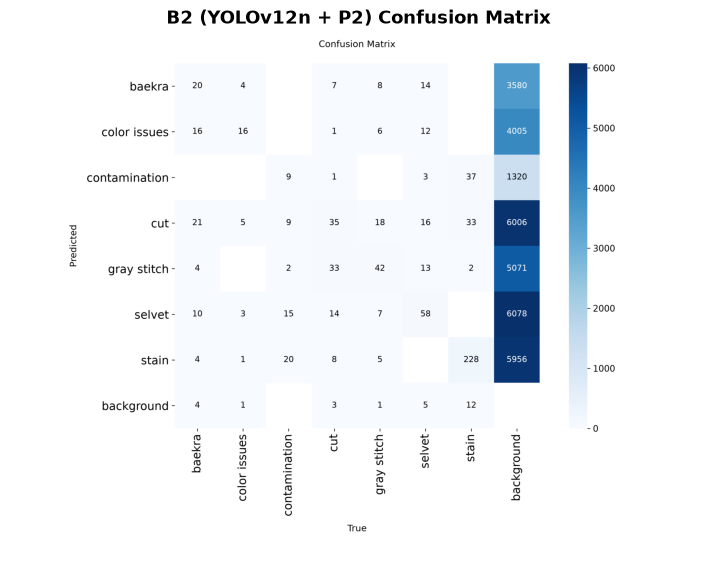

In [43]:
from PIL import Image

cm_path = B2_RUN_DIR / "confusion_matrix.png"
if cm_path.exists():
    plt.figure(figsize=(9, 7))
    plt.imshow(Image.open(cm_path))
    plt.axis("off")
    plt.title("B2 (YOLOv12n + P2) Confusion Matrix", fontsize=13, fontweight="bold")
    plt.show()
else:
    print("Confusion matrix image not found.")


In [44]:
B2_PREDICTION_DIR = OUTPUTS_DIR / "b2_p2_predictions"

b2_predictions = b2_model.predict(
    source=str(DATASET_DIR / "test" / "images"),
    imgsz=IMG_SIZE,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=str(OUTPUTS_DIR),
    name="b2_p2_predictions",
    exist_ok=True,
    verbose=False
)
print("B2 predictions generated successfully.")


Results saved to /content/fabric_defect_detection/outputs/b2_p2_predictions
B2 predictions generated successfully.


In [45]:
b2_prediction_images = []
for extension in ["*.jpg", "*.jpeg", "*.png"]:
    b2_prediction_images.extend(B2_PREDICTION_DIR.glob(extension))

print("Prediction images found:", len(b2_prediction_images))


Prediction images found: 280


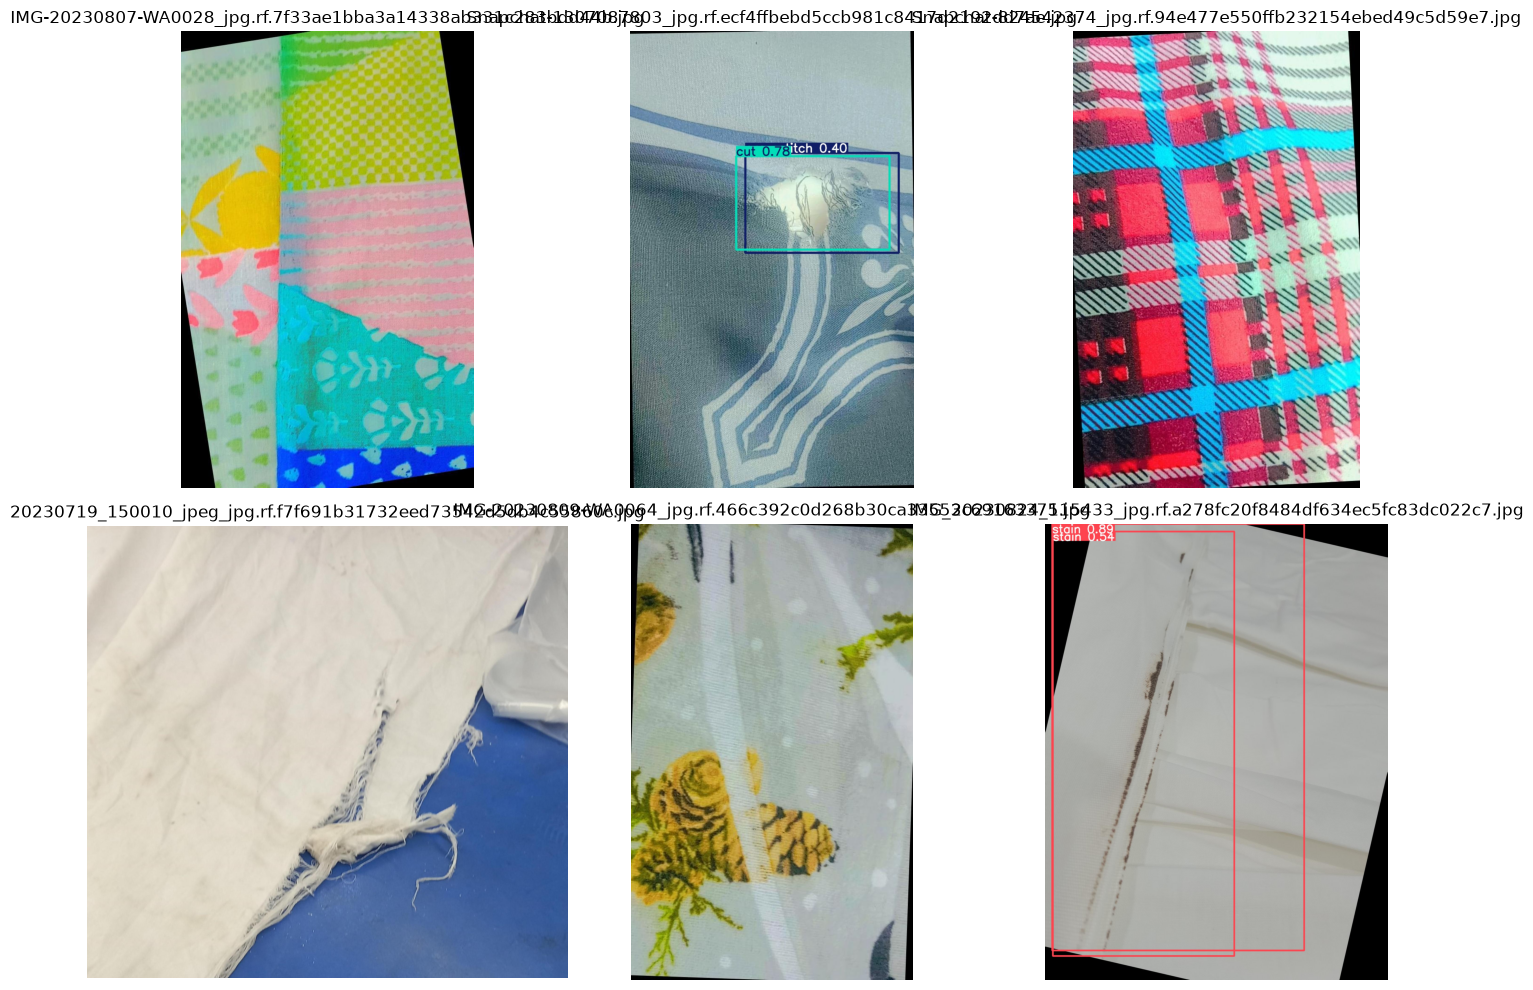

In [46]:
plt.figure(figsize=(14, 10))
for i, image_path in enumerate(b2_prediction_images[:6]):
    image = Image.open(image_path)
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [47]:
B2_FINAL_MODEL = MODELS_DIR / "chenab_yolov12n_p2_best.pt"
shutil.copy2(B2_BEST, B2_FINAL_MODEL)
print("B2 best model saved to:", B2_FINAL_MODEL)


B2 best model saved to: /content/fabric_defect_detection/models/chenab_yolov12n_p2_best.pt


In [48]:
B2_METRICS_JSON = RESULTS_DIR / "b2_p2_metrics.json"

b2_complete_results = {
    "experiment": "B2",
    "model": "YOLOv12n + P2",
    "dataset": "Chenab Textile",
    "input_size": IMG_SIZE,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "device": str(DEVICE),
    "detection_scales": ["P2/4", "P3/8", "P4/16", "P5/32"],
    "test_metrics": b2_results,
    "part_a_baseline": part_a_baseline,
    "absolute_improvement": improvement_b2,
    "relative_improvement_percent": relative_b2,
    "training_time_minutes": training_time / 60,
    "parameter_count": {
        "baseline": int(baseline_params),
        "p2": int(p2_params),
        "additional": int(p2_params - baseline_params)
    }
}

with open(B2_METRICS_JSON, "w", encoding="utf-8") as f:
    json.dump(b2_complete_results, f, indent=4)

print("B2 metrics saved to:", B2_METRICS_JSON)


B2 metrics saved to: /content/fabric_defect_detection/results/b2_p2_metrics.json


In [49]:
baseline_map = part_a_baseline["mAP@0.50:0.95"]
b2_map = b2_results["mAP@0.50:0.95"]
baseline_recall = part_a_baseline["Recall"]
b2_recall = b2_results["Recall"]

print("=" * 70)
print("B2 RESEARCH DECISION")
print("=" * 70)
print()
if b2_map > baseline_map:
    print("✓ P2 improved mAP@0.50:0.95.")
else:
    print("✗ P2 did not improve mAP@0.50:0.95.")
print()
if b2_recall > baseline_recall:
    print("✓ P2 improved Recall.")
else:
    print("✗ P2 did not improve Recall.")
print()
print(f"Baseline mAP50-95 : {baseline_map:.2f}%")
print(f"B2 mAP50-95       : {b2_map:.2f}%")
print()
print(f"Baseline Recall   : {baseline_recall:.2f}%")
print(f"B2 Recall         : {b2_recall:.2f}%")


B2 RESEARCH DECISION

✗ P2 did not improve mAP@0.50:0.95.

✗ P2 did not improve Recall.

Baseline mAP50-95 : 47.42%
B2 mAP50-95       : 29.34%

Baseline Recall   : 70.78%
B2 Recall         : 52.26%


In [50]:
print("=" * 70)
print("B2 — YOLOv12n + P2 RESULTS SUMMARY")
print("=" * 70)

print("\nPART A BASELINE (TEST SET)")
print("--------------------------")
for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    print(f"{metric:15s}: {part_a_baseline[metric]:.2f}%")

print("\nB2 RESULTS (TEST SET)")
print("---------------------")
for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    print(f"{metric:15s}: {b2_results[metric]:.2f}%")

print("\nCHANGE FROM PART A")
print("------------------")
for metric in ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"]:
    diff = b2_results[metric] - part_a_baseline[metric]
    sign = "+" if diff >= 0 else ""
    print(f"{metric:15s}: {sign}{diff:.2f} percentage points")


B2 — YOLOv12n + P2 RESULTS SUMMARY

PART A BASELINE (TEST SET)
--------------------------
Precision      : 79.74%
Recall         : 70.78%
F1-Score       : 74.99%
mAP@0.50       : 80.55%
mAP@0.50:0.95  : 47.42%

B2 RESULTS (TEST SET)
---------------------
Precision      : 63.14%
Recall         : 52.26%
F1-Score       : 57.18%
mAP@0.50       : 58.85%
mAP@0.50:0.95  : 29.34%

CHANGE FROM PART A
------------------
Precision      : -16.60 percentage points
Recall         : -18.52 percentage points
F1-Score       : -17.81 percentage points
mAP@0.50       : -21.70 percentage points
mAP@0.50:0.95  : -18.08 percentage points


In [51]:
B2_TABLE_CSV = RESULTS_DIR / "b2_p2_comparison.csv"
comparison_b2.to_csv(B2_TABLE_CSV, index=False)
print("Saved B2 comparison table to:", B2_TABLE_CSV)


Saved B2 comparison table to: /content/fabric_defect_detection/results/b2_p2_comparison.csv
